# 03 · Trilha 2 — Folguistas e feristas

**Pergunta:** quantos integrantes a mais, por empresa, são necessários para manter o serviço nos dias previstos quando os titulares faltam, tiram férias, apresentam atestado ou se afastam?

**Ideia central.** A *perda de carga* é a fração do trabalho programado que deixa de ser entregue por causa de ausências. Para entregar N posições, a folha precisa de `N / (1 − perda)` pessoas, porque quem está ausente também está na folha. Logo:

`quadro extra = N × perda / (1 − perda)`

A perda é separada em três blocos, porque cada um se comporta de um jeito e pede um tratamento diferente:

| Bloco | O que é | Tratamento |
|---|---|---|
| **Férias** | planejada (30 dias por ano, só para quem tem 1 ano de casa ou mais) | taxa entre elegíveis × parcela do quadro elegível, ligada à rotatividade da Trilha 1 |
| **Afastamento prolongado** | INSS, acidente de trabalho, aposentadoria por incapacidade, licenças | nível médio (é um estado persistente, conhecido após o início) |
| **Ausência curta imprevista** | faltas, atestados de até 15 dias, abonos | nível médio **mais uma reserva**, calibrada pela variabilidade diária, para um nível de serviço de 95% |

Caminho: classificar o ponto, limpar problemas de dados, estimar as taxas, dimensionar a reserva, preencher as células sem dados e calcular o quadro extra por empresa.

In [1]:
import sys; sys.path.insert(0, '../src')
import numpy as np, pandas as pd, matplotlib.pyplot as plt
import ausencias as au, rotatividade as rot

pd.set_option('display.width', 200); pd.set_option('display.max_columns', 40); pd.set_option('display.max_rows', 100)
plt.rcParams.update({'figure.dpi': 100, 'axes.grid': True, 'grid.alpha': .3})
CORTE = rot.CORTE
from statistics import NormalDist

## 1. Dados

In [2]:
ponto_bruto = au.carregar_ponto('../dados')
ponto_bruto['grupo'] = ponto_bruto.FUNCAO.map(au.grupo_funcao)
print(len(ponto_bruto), 'linhas de ponto (vínculo-dia), sem os dias já demitidos')
ponto_bruto.groupby('bloco_dia', dropna=False).size().rename('dias').to_frame().assign(
    significado=lambda x: [{'ferias': 'situação F (férias)', 'prolongada': 'INSS, acidente, aposentadoria por incapacidade, licenças',
                            'curta': 'doença de até 15 dias (situação P sem INSS)'}.get(i, 'dia sem situação de ausência') for i in x.index])

593008 linhas de ponto (vínculo-dia), sem os dias já demitidos


,dias,significado
bloco_dia,,
curta,5712,doença de até 15 dias (situação P sem INSS)
ferias,37915,situação F (férias)
prolongada,26035,"INSS, acidente, aposentadoria por incapacidade..."
NaN,523346,dia sem situação de ausência


In [3]:
# quem tem ponto, frente ao quadro ativo de set/2026
integ = rot.carregar_integrantes('../dados/dim_integrante.csv')
extra = pd.read_csv('../dados/dim_integrante.csv', sep=';', encoding='utf-8-sig', usecols=['ID_INTEGRANTE', 'ID_FUNCAO'])
fun = pd.read_csv('../dados/dim_funcao.csv', sep=';', encoding='utf-8-sig', usecols=['ID_FUNCAO', 'FUNCAO'])
integ = integ.merge(extra, on='ID_INTEGRANTE').merge(fun, on='ID_FUNCAO'); integ['grupo'] = integ.FUNCAO.map(au.grupo_funcao)
ativos = integ[(integ.DATAADMISSAO <= CORTE) & (integ.DATADEMISSAO.isna() | (integ.DATADEMISSAO > CORTE))].copy()
ativos['tempo_m'] = ((CORTE - ativos.DATAADMISSAO).dt.days / 30.44).astype(int)
com_ponto = set(ponto_bruto.ID_INTEGRANTE)
cob = ativos.assign(com_ponto=ativos.ID_INTEGRANTE.isin(com_ponto)).groupby(['CODCOLIGADA', 'grupo']).agg(
    ativos=('com_ponto', 'size'), com_ponto=('com_ponto', 'sum'))
cob['% com ponto'] = (cob.com_ponto / cob.ativos * 100).round(0)
cob

ativos  com_ponto  % com ponto
CODCOLIGADA grupo                                                       
3           Demais                           113         83         73.0
4           Demais                             7          6         86.0
5           Aprendiz                         147          0          0.0
            Cobrador                        1106          0          0.0
            Demais                           536          0          0.0
            Motorista (caminhão e leves)       3          0          0.0
            Motorista de ônibus             1179          0          0.0
6           Aprendiz                          37         21         57.0
            Demais                           128        117         91.0
            Motorista (caminhão e leves)     585        581         99.0
            Motorista de ônibus               47         46         98.0
7           Demais                            45         42         93.0
8           Aprendiz                          45         45        100.0
            Demais                           223        194         87.0
            Motorista (caminhão e leves)       9          9        100.0
            Motorista de ônibus              746          0          0.0

**O que os dados cobrem.** `fBatidas` tem uma linha por vínculo por dia (99,6% dos dias de vínculo das pessoas que aparecem lá) e `fAfastamentos` só contém integrantes que também estão em `fBatidas`. Ou seja, **toda a informação de ausência vem da mesma subpopulação de ~1.900 pessoas**.

A situação do dia no ponto identifica a causa: `F` = férias, `P` = doença ou INSS, `T` = acidente de trabalho, `I`, `L`, `M`, `E` e `Y` = aposentadoria por incapacidade, licenças e outros. Nos dias de férias e de afastamento longo a jornada prevista é zero, então esses dias **não aparecem como falta** e precisam ser contados pela situação, usando a carga que o integrante teria no dia.

**Cobertura frente ao quadro ativo de set/2026 (tabela acima).** Dos 4.727 ativos operacionais (sem aprendizes), **3.570 (76%) não têm nenhuma linha de ponto**: toda a empresa 5 (2.824) e os 746 motoristas de ônibus da empresa 8. As empresas 6 e 3 e as funções "demais" da 8 estão bem cobertas. Esse é o principal limite desta trilha e orienta o desenho do resultado.

## 2. Limpeza do ponto

In [4]:
ponto, rel = au.limpar_ponto(ponto_bruto)
rel

{'corte_inicio_por_empresa': {3: '2025-01-20', 8: '2025-03-20'},
 'linhas_removidas_sem_registro': 14131,
 'dias_abono_coletivo': ['2025-03-03',
  '2025-03-04',
  '2025-12-24',
  '2025-12-31',
  '2026-02-16',
  '2026-02-17'],
 'linhas_removidas_abono_coletivo': 4588,
 'linhas_antes': 593008,
 'linhas_depois': 574289}

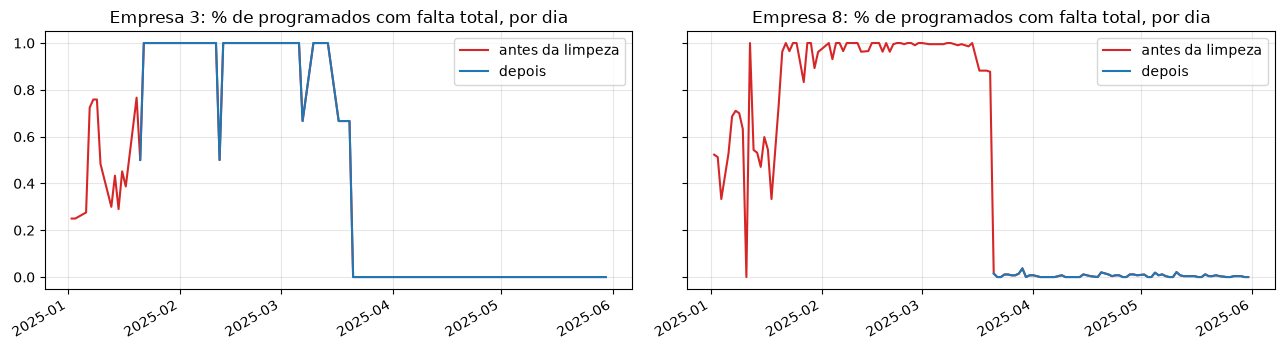

In [5]:
# efeito da limpeza: falta diaria (% dos programados sem trabalhar e sem abono) nas empresas 3 e 8
def falta_diaria(d, emp):
    x = d[(d.empresa == emp) & (d.MINUTOS_PREVISTOS > 0) & d.bloco_dia.isna() & (d.FERIADO == 0)]
    return (x.MINUTOS_FALTA >= .9 * x.MINUTOS_PREVISTOS).groupby(x.DATA).mean()

fig, ax = plt.subplots(1, 2, figsize=(13, 3.6), sharey=True)
for a, emp in zip(ax, (3, 8)):
    falta_diaria(ponto_bruto, emp).loc['2025-01-01':'2025-05-31'].plot(ax=a, color='C3', label='antes da limpeza')
    falta_diaria(ponto, emp).loc['2025-01-01':'2025-05-31'].plot(ax=a, color='C0', label='depois')
    a.set_title(f'Empresa {emp}: % de programados com falta total, por dia'); a.set_xlabel(''); a.legend()
plt.tight_layout(); plt.show()

Dois problemas de dados foram encontrados, e ambos distorceriam as taxas:

1. **Início sem registro.** Nas empresas 3 e 8, até 20/01/2025 e 20/03/2025 respectivamente, quase 100% dos dias programados aparecem como falta total (gráfico acima, em vermelho), e depois a taxa cai para menos de 1%. O ponto dessas empresas evidentemente não registrava batidas nesse período. Sem a correção, a ausência curta das funções "demais" da empresa 8 sairia em 9,5% em vez de 3,0%. Foram removidas 14.131 linhas.
2. **Abono coletivo.** Em 6 dias (03 e 04/03/2025, 24 e 31/12/2025, 16 e 17/02/2026) mais de 15% da carga de toda a população recebeu abono: Carnaval e vésperas de feriado. São previsíveis pelo calendário, e não imprevisto. Foram removidas 4.588 linhas.

Total removido: 18.719 de 593.008 linhas (3,2%).

## 3. Perda de carga por causa

In [6]:
agg = au.agregar_por_integrante(ponto)
op = agg[agg.grupo != 'Aprendiz']        # aprendizes ficam de fora (ver texto)
linhas = []
for (e, g), x in agg.groupby(['empresa', 'grupo']):
    t = au.taxas(x)
    linhas.append({'empresa': e, 'grupo': g, 'integrantes': x.ID_INTEGRANTE.nunique(), 'pessoa_dia': int(x.dias.sum()),
                   'férias (≥1 ano de casa)': t['ferias'] * 100, 'prolongada': t['prolongada'] * 100, 'curta': t['curta'] * 100})
tab = pd.DataFrame(linhas).set_index(['empresa', 'grupo']); tab.round(2)

integrantes  pessoa_dia  férias (≥1 ano de casa)  prolongada  curta
empresa grupo                                                                                            
1       Demais                                 39        7810                     9.47        3.60   9.75
3       Demais                                 98       33069                     4.07        0.34   2.42
4       Demais                                  6         938                      NaN        0.00   2.28
6       Aprendiz                               35        7188                     0.00        0.00  34.56
        Demais                                176       69239                     7.45        3.09   2.12
        Motorista (caminhão e leves)          972      263479                     8.68        5.78   2.96
        Motorista de ônibus                    57       15999                     8.40       11.00   2.23
7       Demais                                 46       19125                     3.90        6.18  15.33
8       Aprendiz                               99       24566                     8.78        4.20  26.77
        Demais                                348      127881                     8.93        2.54   2.95
        Motorista (caminhão e leves)            9        4995                     7.08        0.00   0.84

**Leitura da tabela.**

- **Motoristas de caminhão e veículos leves da empresa 6** (972 pessoas, a célula mais robusta): férias 8,7%, afastamento prolongado 5,8% (INSS pesa muito) e ausência curta 3,0%.
- **Funções "demais" das empresas 6 e 8** (176 e 348 pessoas): prolongada de 2,5% a 3,1%, curta de 2,1% a 3,0%.
- **Empresa 3**: férias de apenas 4,1%, porque metade do quadro tem menos de 1 ano de casa (efeito explicado abaixo).
- **Empresas 1, 4 e 7**: amostras pequenas ou atípicas (a empresa 1 foi encerrada, a 4 tem 6 pessoas, a 7 tem 46 e curta de 15,3% por poucos eventos). Entram com peso baixo.
- **Aprendizes** têm ausência curta de 27% a 35%: as horas de estudo do contrato de aprendizagem são abonadas. Não é ausência a cobrir, então **aprendizes ficam fora do dimensionamento** (229 ativos).
- **Motoristas de ônibus (empresa 6, 57 pessoas)**: prolongada de 11% por pouquíssimos casos longos. Amostra fina.

In [7]:
# efeito do tempo de casa
x = ponto[ponto.grupo != 'Aprendiz'].copy()
x['faixa'] = pd.cut(x.anos_casa, [-1, .5, 1, 2, 5, 100], labels=['<6m', '6m-1a', '1-2a', '2-5a', '>5a'])
x['falta'] = np.where(x.bloco_dia.isna(), np.minimum(x.MINUTOS_PREVISTOS, x.MINUTOS_FALTA), 0)
tc = x.groupby('faixa', observed=True).apply(lambda g: pd.Series({
    'férias': g.perda_ferias.sum() / g.esperado.sum() * 100, 'prolongada': g.perda_prolongada.sum() / g.esperado.sum() * 100,
    'curta': g.perda_curta.sum() / g.esperado.sum() * 100, 'faltas (parte da curta)': g.falta.sum() / g.esperado.sum() * 100,
    'pessoa-dias': len(g)}), include_groups=False)
tc.round(2)

,férias,prolongada,curta,faltas (parte da curta),pessoa-dias
faixa,,,,,
<6m,0.00,0.63,5.05,3.14,111241.0
6m-1a,0.01,0.81,4.13,1.52,41491.0
1-2a,8.16,3.00,4.09,1.18,71992.0
2-5a,8.38,6.40,2.52,0.46,128934.0
>5a,8.03,6.39,2.43,0.55,188727.0


O **tempo de casa muda tudo**, e é o que liga esta trilha à Trilha 1:

- **Férias:** praticamente zero abaixo de 1 ano de casa e de 8,0% a 8,4% depois, próximo dos 30 dias por ano da lei (30/365 = 8,2%), mas veja a ressalva logo abaixo: parte desses dias não é férias. Por isso a taxa de férias de uma empresa depende da parcela do quadro que já tem direito.
- **Ausência curta:** 5,1% nos primeiros 6 meses contra 2,4% a 2,5% com mais de 2 anos. Só as faltas vão de 3,1% para 0,5%.
- **Afastamento prolongado:** cresce com o tempo de casa (0,6% abaixo de 6 meses, ~6,4% acima de 2 anos), porque os casos de INSS se concentram em quem está há mais tempo.

Consequência: empresas com rotatividade alta têm **menos férias** (muita gente ainda sem direito) e **mais faltas** (muita gente nova).

In [8]:
# ressalva: sequencias de ferias no ponto mais longas que o limite legal (30 dias por periodo aquisitivo)
fb = pd.read_csv('../dados/fBatidas.csv', sep=';', encoding='utf-8-sig',
                 usecols=['ID_INTEGRANTE', 'CODCOLIGADA', 'DATA', 'SITUACAO_NA_DATA'], parse_dates=['DATA'])
fe = fb[fb.SITUACAO_NA_DATA == 'F'].sort_values(['ID_INTEGRANTE', 'DATA'])
bloco = (fe.groupby('ID_INTEGRANTE').DATA.diff().dt.days != 1).cumsum()
dur = fe.groupby(bloco).DATA.transform('size')
seq = pd.DataFrame({'dias F no ponto': fe.groupby('CODCOLIGADA').size(),
                    'em sequências > 30 dias': fe[dur > 30].groupby('CODCOLIGADA').size(),
                    'em sequências > 60 dias': fe[dur > 60].groupby('CODCOLIGADA').size()}).fillna(0).astype(int)
seq.loc['total'] = seq.sum()
seq['% em > 30 dias'] = (100 * seq['em sequências > 30 dias'] / seq['dias F no ponto']).round(1)
print(f'{fe.ID_INTEGRANTE[dur > 30].nunique()} vínculos com "férias" contínuas de mais de 30 dias; maior sequência: {dur.max()} dias')
seq

75 vínculos com "férias" contínuas de mais de 30 dias; maior sequência: 472 dias


,dias F no ponto,em sequências > 30 dias,em sequências > 60 dias,% em > 30 dias
CODCOLIGADA,,,,
1,611,0,0,0.0
3,694,0,0,0.0
6,24050,6384,5017,26.5
7,557,0,0,0.0
8,12003,2553,2553,21.3
total,37915,8937,7570,23.6


**Ressalva sobre a validação das férias.** Parte dos dias marcados como férias (`F`) no ponto está em sequências contínuas de mais de 30 dias, e uma parte em sequências de mais de 60, o que não é compatível com férias pela CLT (provavelmente são afastamentos longos registrados como férias). Por isso a coincidência da taxa entre elegíveis com 30/365 = 8,2% **não deve ser lida como validação**: a taxa de férias propriamente dita é provavelmente menor e a de afastamento prolongado, maior. **O quadro extra total quase não muda**, porque esses dias continuam sendo ausência que precisa de cobertura; muda só a divisão entre os blocos.

In [9]:
# validacao do mecanismo de ferias: empresa 6, motoristas. Prever ferias de jan-set/2026 com a taxa de 2025
# (so quem tem >=1 ano) x parcela elegivel de 2026, contra a taxa media de 2025 sem ajuste
m = ponto[(ponto.empresa == 6) & (ponto.grupo == 'Motorista (caminhão e leves)')].copy()
m = m[m.DATA.dt.month.between(3, 9) | (m.DATA.dt.year == 2026)]
def ferias_stats(g):
    el = g[g.elegivel_ferias]
    return pd.Series({'férias observada (% da carga)': g.perda_ferias.sum() / g.esperado.sum() * 100,
                      'taxa entre elegíveis': el.perda_ferias.sum() / el.esperado.sum() * 100,
                      'parcela elegível (% da carga)': el.esperado.sum() / g.esperado.sum() * 100})
per = {'mar-set/2025': m[(m.DATA >= '2025-03-01') & (m.DATA <= '2025-09-30')], 'jan-set/2026': m[m.DATA.dt.year == 2026]}
v = pd.DataFrame({k: ferias_stats(g) for k, g in per.items()}).T
v['previsto 2026 pelo mecanismo'] = np.nan
v.loc['jan-set/2026', 'previsto 2026 pelo mecanismo'] = v.loc['mar-set/2025', 'taxa entre elegíveis'] * v.loc['jan-set/2026', 'parcela elegível (% da carga)'] / 100
v.loc['jan-set/2026', 'previsto 2026 sem ajuste (taxa média de 2025)'] = v.loc['mar-set/2025', 'férias observada (% da carga)']
v.round(2)

,férias observada (% da carga),taxa entre elegíveis,parcela elegível (% da carga),previsto 2026 pelo mecanismo,previsto 2026 sem ajuste (taxa média de 2025)
mar-set/2025,6.94,8.12,85.49,NaN,NaN
jan-set/2026,4.61,8.69,53.06,4.31,6.94


**Validação do mecanismo de férias.** Na empresa 6 (motoristas), as férias caíram de 6,9% (mar-set/2025) para 4,6% (jan-set/2026). A razão não é mudança de comportamento: em 2026 só 53% da carga vem de quem tem 1 ano de casa ou mais, contra 85% em 2025 (muita contratação). Aplicando a taxa de 2025 entre elegíveis (8,1%) à parcela elegível de 2026, o mecanismo prevê **4,3%**, contra **4,6% observado**. Usar a média de 2025 sem esse ajuste preveria 6,9%, um erro de 2,3 p.p.

## 3b. Validação fora da amostra

In [10]:
# (1) validacao no tempo: estima com mar-dez/2025 e preve jan-set/2026, celula a celula
def por_integrante(d):
    return au.agregar_por_integrante(d[d.grupo != 'Aprendiz'])
treino = por_integrante(ponto[(ponto.DATA >= '2025-03-21') & (ponto.DATA <= '2025-12-31')])
teste = por_integrante(ponto[ponto.DATA >= '2026-01-01'])
CEL = [(6, 'Motorista (caminhão e leves)'), (6, 'Demais'), (8, 'Demais'), (3, 'Demais')]
linhas = []
for emp_, grp in CEL:
    a_tr = treino[(treino.empresa == emp_) & (treino.grupo == grp)]; a_te = teste[(teste.empresa == emp_) & (teste.grupo == grp)]
    t_tr, t_te = au.taxas(a_tr), au.taxas(a_te)
    el_tr, el_te = a_tr.esp_1a.sum() / a_tr.esp.sum(), a_te.esp_1a.sum() / a_te.esp.sum()
    ferias_obs_tr = t_tr['ferias'] * el_tr                      # férias observadas em 2025 (% da carga)
    ferias_obs_te = t_te['ferias'] * el_te
    comp = {'férias (mecanismo)': (t_tr['ferias'] * el_te, ferias_obs_te), 'férias (sem ajuste)': (ferias_obs_tr, ferias_obs_te),
            'prolongada': (t_tr['prolongada'], t_te['prolongada']), 'curta': (t_tr['curta'], t_te['curta'])}
    tot_mec = t_tr['ferias'] * el_te + t_tr['prolongada'] + t_tr['curta']; tot_sem = ferias_obs_tr + t_tr['prolongada'] + t_tr['curta']
    tot_obs = ferias_obs_te + t_te['prolongada'] + t_te['curta']
    n_tr = a_tr.ID_INTEGRANTE.nunique(); Z = n_tr / (n_tr + 100)             # metodo completo: credibilidade contra a referencia do treino
    ref_tr = au.taxas(treino)
    mix = lambda k: Z * (t_tr[k] if not np.isnan(t_tr[k]) else ref_tr[k]) + (1 - Z) * ref_tr[k]
    tot_cred = mix('ferias') * el_te + mix('prolongada') + mix('curta')
    linhas.append({'empresa': emp_, 'grupo': grp, 'integrantes teste': a_te.ID_INTEGRANTE.nunique(),
                   'perda observada 2026 (%)': tot_obs * 100, 'prevista c/ mecanismo (%)': tot_mec * 100, 'erro (p.p.)': (tot_mec - tot_obs) * 100,
                   'prevista sem ajuste (%)': tot_sem * 100, 'erro sem ajuste (p.p.)': (tot_sem - tot_obs) * 100,
                   'prevista c/ credibilidade (%)': tot_cred * 100, 'erro c/ credibilidade (p.p.)': (tot_cred - tot_obs) * 100,
                   **{f'{k}: previsto/obs. (p.p.)': f'{v[0]*100:.1f} / {v[1]*100:.1f}' for k, v in comp.items()}})
bt = pd.DataFrame(linhas).set_index(['empresa', 'grupo'])
bt[['perda observada 2026 (%)', 'prevista sem ajuste (%)', 'erro sem ajuste (p.p.)', 'prevista c/ mecanismo (%)', 'erro (p.p.)', 'prevista c/ credibilidade (%)', 'erro c/ credibilidade (p.p.)']].round(1)

perda observada 2026 (%)  prevista sem ajuste (%)  erro sem ajuste (p.p.)  prevista c/ mecanismo (%)  erro (p.p.)  prevista c/ credibilidade (%)  \
empresa grupo                                                                                                                                                                            
6       Motorista (caminhão e leves)                      12.7                     16.3                     3.6                       13.8          1.1                           13.5   
        Demais                                            10.6                     11.5                     0.9                       10.8          0.2                           12.2   
8       Demais                                            13.5                     12.1                    -1.4                       12.7         -0.8                           13.2   
3       Demais                                             6.2                      1.9                    -4.4                        1.9         -4.4                            8.5   

                                      erro c/ credibilidade (p.p.)  
empresa grupo                                                       
6       Motorista (caminhão e leves)                           0.8  
        Demais                                                 1.6  
8       Demais                                                -0.3  
3       Demais                                                 2.2

**Validação no tempo.** Estimando com mar–dez/2025 e prevendo jan–set/2026, o método completo (taxa de cada célula combinada com a referência por credibilidade, e férias ajustadas pela parcela com direito em 2026) erra **de −0,3 a +2,2 p.p.** de perda total, com erro médio absoluto de **1,2 p.p.**, contra 2,6 p.p. se não se ajusta o tempo de casa. Nas empresas 6 (caminhão: 13,5% previsto contra 12,7% observado) e 8 ("demais": 13,2% contra 13,5%) o ajuste de férias é o que melhora o resultado.

A empresa 3 mostra por que a credibilidade existe: sem ela o erro é de −4,4 p.p., porque o treino de 2025 não tem ninguém com 1 ano de casa, então a taxa própria de férias não existe e a de afastamento prolongado é zero. Com a credibilidade, a referência preenche o que a célula não tem, e o erro cai para +2,2. O custo disso aparece na empresa 6 "demais", em que a credibilidade piora um pouco (+1,6 contra +0,2 p.p.), porque a célula já tinha dado suficiente.

In [11]:
# (2) extrapolacao: preve uma celula com as taxas de todas as OUTRAS celulas (o que fazemos com a empresa 5)
op_agg = au.agregar_por_integrante(ponto[ponto.grupo != 'Aprendiz'])
linhas = []
for emp_, grp in CEL:
    alvo = op_agg[(op_agg.empresa == emp_) & (op_agg.grupo == grp)]
    outros = op_agg[~((op_agg.empresa == emp_) & (op_agg.grupo == grp))]
    pre, obs = au.taxas(outros), au.taxas(alvo)
    por_cel = {(e2, g2): au.taxas(x) for (e2, g2), x in outros.groupby(['empresa', 'grupo']) if x.ID_INTEGRANTE.nunique() >= 40}
    tot_cel = [sum(t.values()) for t in por_cel.values()]
    linhas.append({'célula omitida': f'{emp_} · {grp}', 'integrantes': alvo.ID_INTEGRANTE.nunique(),
                   'previsto (%)': sum(pre.values()) * 100, 'observado (%)': sum(obs.values()) * 100, 'erro (p.p.)': (sum(pre.values()) - sum(obs.values())) * 100,
                   'faixa das outras células (%)': f'{min(tot_cel)*100:.1f} a {max(tot_cel)*100:.1f}',
                   'dentro da faixa?': min(tot_cel) <= sum(obs.values()) <= max(tot_cel),
                   'férias / prolongada / curta (obs.)': ' / '.join(f'{obs[k]*100:.1f}' for k in ('ferias', 'prolongada', 'curta')),
                   'férias / prolongada / curta (prev.)': ' / '.join(f'{pre[k]*100:.1f}' for k in ('ferias', 'prolongada', 'curta'))})
loco = pd.DataFrame(linhas).set_index('célula omitida')
rmse_todas = float(np.sqrt((loco['erro (p.p.)'] ** 2).mean())); rmse_sem3 = float(np.sqrt((loco['erro (p.p.)'].iloc[:3] ** 2).mean()))
import os; os.makedirs('../resultados', exist_ok=True)
pd.DataFrame({'rmse_pp': [rmse_todas, rmse_sem3], 'celulas': ['todas (4)', 'sem a empresa 3 (3)']}).to_csv('../resultados/trilha2_erro_extrapolacao.csv', index=False, encoding='utf-8-sig')
print(f'erro de extrapolação (RMSE): {rmse_todas:.1f} p.p. com as 4 células, {rmse_sem3:.1f} p.p. sem a empresa 3')
loco.round(1)

erro de extrapolação (RMSE): 5.4 p.p. com as 4 células, 2.9 p.p. sem a empresa 3


,integrantes,previsto (%),observado (%),erro (p.p.),faixa das outras células (%),dentro da faixa?,férias / prolongada / curta (obs.),férias / prolongada / curta (prev.)
célula omitida,,,,,,,,
6 · Motorista (caminhão e leves),972,14.5,17.4,-2.9,6.8 a 25.4,True,8.7 / 5.8 / 3.0,7.7 / 3.1 / 3.6
6 · Demais,176,16.4,12.7,3.7,6.8 a 25.4,True,7.4 / 3.1 / 2.1,8.3 / 4.6 / 3.5
8 · Demais,348,16.3,14.4,1.9,6.8 a 25.4,True,8.9 / 2.5 / 3.0,7.9 / 5.0 / 3.4
3 · Demais,98,16.4,6.8,9.6,12.7 a 25.4,False,4.1 / 0.3 / 2.4,8.4 / 4.7 / 3.4


**Extrapolação (é o que fazemos com a empresa 5).** Prever cada célula usando só as outras erra −2,9, +3,7 e +1,9 p.p. de perda (caminhão da empresa 6, "demais" das empresas 6 e 8) e **+9,6 p.p. na empresa 3**, que tem taxas bem menores (prolongada de 0,3% e férias de 4,1% mesmo entre elegíveis). O erro quadrático médio é de **5,4 p.p.** com as 4 células e de 2,9 p.p. sem a empresa 3.

Duas conclusões. **(1)** A faixa baixo–alto que usamos para células sem dado (cerca de ±1,6 p.p. de perda na empresa 5) é **estreita demais** frente ao erro de extrapolação observado. **(2)** O erro vem sobretudo de heterogeneidade real entre empresas, que só o dado próprio elimina. O modelo integrado (notebook 05) incorpora esse erro como uma fonte de incerteza separada.

## 4. Ausência curta: variabilidade diária e nível de serviço

In [12]:
o = ponto[ponto.grupo != 'Aprendiz']
dia = o.groupby('DATA').agg(c=('perda_curta', 'sum'), e=('esperado', 'sum'), n=('ID_INTEGRANTE', 'nunique'))
dia = dia[dia.n >= 100]; dia['p'] = dia.c / dia.e
dia = dia[dia.e > dia.e.median() * .5]                     # dias com jornada relevante (tira domingos e folgas coletivas)
p_med, n_med = dia.p.mean(), dia.n.mean()
var_obs, var_bin = dia.p.var(), p_med * (1 - p_med) / n_med
SIGMA2 = max(0, var_obs - var_bin)
dia[['p', 'n']].to_csv('../resultados/trilha2_ausencia_curta_diaria.csv', encoding='utf-8-sig')   # insumo do notebook 06
pd.Series({'dias analisados': len(dia), 'ausência curta média diária': p_med, 'P95 empírico': dia.p.quantile(.95), 'P99 empírico': dia.p.quantile(.99),
           'variância observada': var_obs, 'variância se fossem independentes (binomial)': var_bin, 'choque comum (desvio)': SIGMA2 ** .5}).round(4).to_frame('valor')

,valor
dias analisados,551.0000
ausência curta média diária,0.0328
P95 empírico,0.0559
P99 empírico,0.0953
variância observada,0.0003
variância se fossem independentes (binomial),0.0000
choque comum (desvio),0.0147


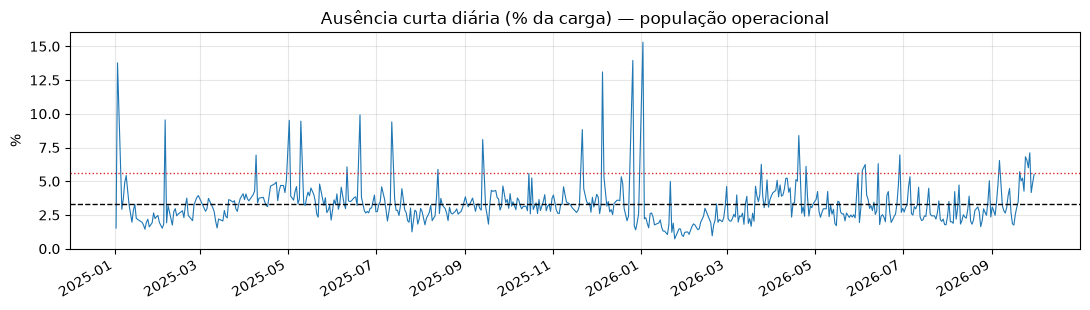

In [13]:
ax = dia.p.mul(100).plot(figsize=(11, 3.2), lw=.8); ax.axhline(p_med * 100, color='k', ls='--', lw=1)
ax.axhline(dia.p.quantile(.95) * 100, color='C3', ls=':', lw=1); ax.set_title('Ausência curta diária (% da carga) — população operacional'); ax.set_xlabel(''); ax.set_ylabel('%')
plt.tight_layout(); plt.show()

In [14]:
# reserva extra (p.p. acima da media) para cobrir o dia com nivel de servico escolhido
from statistics import NormalDist
niveis = [.90, .95, .99]
pd.DataFrame({f'{int(nv*100)}%': {f'{N} posições': (au.reserva_curta(p_med, SIGMA2, N, z=NormalDist().inv_cdf(nv)) - p_med) * 100 for N in (50, 500, 3000)}
              for nv in niveis}).round(2)

,90%,95%,99%
50 posições,3.74,4.79,6.78
500 posições,2.14,2.75,3.88
3000 posições,1.93,2.47,3.49


Se as faltas de cada pessoa fossem independentes, a taxa diária de ausência curta variaria pouco (variância de ~0,00004). A variância observada é de ~0,00025, ou seja, ~7 vezes maior: há **choques comuns** que atingem muita gente no mesmo dia (desvio de ~1,5 p.p.). Por isso não basta cobrir a média de 3,3%: o dia ruim (P95) chega a 5,6% e o P99 a 9,5%.

A reserva é a distância entre a média e o dia que queremos cobrir (o nível de serviço). O choque comum não diminui com o tamanho da operação, então a reserva também não: ~1,9 a 2,1 p.p. para 90%, ~2,5 a 2,75 p.p. para 95% e 3,5 a 3,9 p.p. para 99%, tanto em 500 quanto em 3.000 posições. Só em operações muito pequenas (50 posições) a parte binomial pesa (+4,8 p.p. a 95%).

O nível de serviço de 95% é o caso base. A sensibilidade a 90% e 99% está na seção 6.

In [15]:
# sensibilidade: dias programados, sem nenhuma batida e sem falta nem abono registrados (tratados como sem perda)
ponto_op = ponto[ponto.grupo != 'Aprendiz']
x = ponto_op[(ponto_op.MINUTOS_PREVISTOS > 0) & ponto_op.bloco_dia.isna() & (ponto_op.FERIADO == 0) &
             (ponto_op.MINUTOS_TRABALHADOS == 0) & (ponto_op.MINUTOS_FALTA == 0) & (ponto_op.MINUTOS_ABONO == 0)]
pd.Series({'dias': len(x), 'em segunda ou domingo (%)': x.DATA.dt.dayofweek.isin([0, 6]).mean() * 100,
           'empresa 6 (%)': (x.empresa == 6).mean() * 100,
           'carga que seria perdida se fossem faltas (p.p.)': x.MINUTOS_PREVISTOS.sum() / ponto_op.esperado.sum() * 100}).round(2).to_frame('valor')

,valor
dias,13211.00
em segunda ou domingo (%),51.81
empresa 6 (%),98.65
carga que seria perdida se fossem faltas (p.p.),3.05


**Um ponto de atenção.** Há 13.211 dias programados, sem nenhuma batida e sem falta nem abono registrados. São tratados aqui como **sem perda**. Estão concentrados em sábados e domingos (54%) e **98,7% são da empresa 6**. A hipótese é banco de horas ou folga compensada: na empresa 6, a hora extra total (6,4 milhões de minutos) é da mesma ordem que a carga desses dias (5,6 milhões), então o trabalho extra feito antes cobre esses dias.

Mas é uma hipótese que os dados não confirmam. Se fossem faltas, a carga perdida subiria 3,05 p.p. no conjunto operacional (4,65 p.p. na empresa 6), e o quadro extra da empresa 6 iria de ~18% para ~25%. Fica registrado como risco.

## 5. Preenchimento das células sem dados e referência de quadro

In [16]:
ORIGEM = pd.Timestamp('2026-09-01')
painel = rot.painel_tempo_casa(integ)
op_all = op
REF = au.taxas(op_all)                                              # referência geral (população operacional com ponto)
REF_B = au.taxas(op_all[op_all.grupo == 'Demais'])                  # cenário baixo (menos prolongadas)
REF_A = au.taxas(op_all[op_all.grupo.str.startswith('Motorista')])  # cenário alto (motoristas)
pd.DataFrame({'baixo (demais funções)': REF_B, 'base (todos operacionais)': REF, 'alto (motoristas)': REF_A}).mul(100).round(2)

,baixo (demais funções),base (todos operacionais),alto (motoristas)
ferias,7.71,8.17,8.62
prolongada,2.70,4.42,5.97
curta,3.76,3.30,2.88


In [17]:
K = 100   # peso de credibilidade: a celula com n integrantes pesa n/(n+K) contra a referencia
rows = []
for (e, g), x in ativos[ativos.grupo != 'Aprendiz'].groupby(['CODCOLIGADA', 'grupo']):
    N = len(x)
    cell = op_all[(op_all.empresa == e) & (op_all.grupo == g)]; n = cell.ID_INTEGRANTE.nunique()
    risco = rot.risco_por_faixa(painel, e, ORIGEM)
    elegivel = au.participacao_elegivel(x.tempo_m.values, risco, 36)
    s = [elegivel[:12].mean(), elegivel[12:24].mean(), elegivel[24:].mean()]
    Z = n / (n + K)
    if n:
        pt = au.taxas(cell); boot = au.bootstrap_taxas(cell, n=200)
        lo, hi = boot.quantile(.1), boot.quantile(.9)
        pt = {k: (v if not np.isnan(v) else REF[k]) for k, v in pt.items()}
        lo = lo.fillna(pd.Series(REF_B)); hi = hi.fillna(pd.Series(REF_A))
    else:
        pt, lo, hi = REF, pd.Series(REF_B), pd.Series(REF_A)
    mix = lambda own, ref: {k: Z * own[k] + (1 - Z) * ref[k] for k in ('ferias', 'prolongada', 'curta')}
    rows.append({'empresa': e, 'grupo': g, 'ativos': N, 'integrantes_com_dados': n, 'peso_dados': Z,
                 'pct_1ano_atual': (x.tempo_m >= 12).mean(), 's_ano1': s[0], 's_ano2': s[1], 's_ano3': s[2],
                 'base': mix(pt, REF), 'baixo': mix(lo, REF_B), 'alto': mix(hi, REF_A)})
cel = pd.DataFrame(rows)
vis = cel[['empresa', 'grupo', 'ativos', 'integrantes_com_dados', 'peso_dados', 'pct_1ano_atual', 's_ano1', 's_ano3']].copy()
vis['férias (≥1a)'] = cel.base.map(lambda b: b['ferias'] * 100); vis['prolongada'] = cel.base.map(lambda b: b['prolongada'] * 100)
vis['curta'] = cel.base.map(lambda b: b['curta'] * 100)
vis.set_index(['empresa', 'grupo']).round(2)

ativos  integrantes_com_dados  peso_dados  pct_1ano_atual  s_ano1  s_ano3  férias (≥1a)  prolongada  curta
empresa grupo                                                                                                                                   
3       Demais                           113                     98        0.49            0.50    0.67    0.88          6.14        2.40   2.87
4       Demais                             7                      6        0.06            0.14    0.32    0.73          8.17        4.17   3.24
5       Cobrador                        1106                      0        0.00            0.89    0.90    0.93          8.17        4.42   3.30
        Demais                           536                      0        0.00            0.90    0.90    0.93          8.17        4.42   3.30
        Motorista (caminhão e leves)       3                      0        0.00            1.00    0.97    0.93          8.17        4.42   3.30
        Motorista de ônibus             1179                      0        0.00            0.96    0.96    0.95          8.17        4.42   3.30
6       Demais                           128                    176        0.64            0.74    0.72    0.62          7.71        3.57   2.55
        Motorista (caminhão e leves)     585                    972        0.91            0.45    0.48    0.56          8.64        5.66   2.99
        Motorista de ônibus               47                     57        0.36            0.45    0.43    0.56          8.25        6.81   2.91
7       Demais                            45                     46        0.32            0.78    0.85    0.95          6.82        4.97   7.09
8       Demais                           223                    348        0.78            0.85    0.83    0.79          8.76        2.96   3.03
        Motorista (caminhão e leves)       9                      9        0.08            1.00    0.93    0.82          8.08        4.05   3.10
        Motorista de ônibus              746                      0        0.00            0.82    0.82    0.80          8.17        4.42   3.30

**Como cada célula (empresa × grupo de função) é preenchida.**

- A taxa de cada célula é uma média ponderada entre a **própria taxa** e a **referência geral** (todos os operacionais com ponto), com peso de credibilidade `n / (n + 100)`, onde `n` é o número de integrantes da célula com ponto. A célula de caminhão da empresa 6 (972 pessoas) pesa 91% nos próprios dados, a de motoristas de ônibus da empresa 6 (57) pesa 36%, e uma célula **sem nenhum dado** (empresa 5, ônibus da empresa 8) fica 100% na referência geral.
- **Cenários.** Para as células sem dados, o cenário baixo usa as taxas das funções "demais" (menos afastamento prolongado) e o alto usa as dos motoristas (mais prolongado). Para as com dados, entra também o intervalo de reamostragem por integrante (P10 a P90).
- **Férias e tempo de casa.** A taxa de férias entre elegíveis é multiplicada pela parcela do quadro com mais de 12 meses de casa, **projetada mês a mês** com o modelo de risco por tempo de casa da Trilha 1 (quadro estável, quem sai é reposto por um contratado novo). Isso depende da rotatividade: nos motoristas de caminhão da empresa 6, a parcela elegível fica em ~48% no ano 1 e ~56% no ano 3, e na empresa 5, em ~90% a ~96% nos dois anos.
- **Quadro de referência.** O número de posições a cobrir é o quadro ativo operacional em 30/09/2026 (sem aprendizes), a mesma referência da Trilha 1.

## 6. Quadro extra por empresa

In [18]:
Z95 = NormalDist().inv_cdf(.95)
quadro_empresa = ativos[ativos.grupo != 'Aprendiz'].groupby('CODCOLIGADA').size()
def extra_celula(c, cenario, ano, z=Z95):
    t = getattr(c, cenario); s = [c.s_ano1, c.s_ano2, c.s_ano3][ano - 1]
    N_e = quadro_empresa[c.empresa]
    reserva = au.reserva_curta(t['curta'], SIGMA2, N_e, z) - t['curta']     # a reserva é do dia, comum à empresa
    ex, perda = au.quadro_extra(c.ativos, t['ferias'] * s, t['prolongada'], t['curta'] + reserva)
    return ex, perda

linhas = []
for c in cel.itertuples():
    for cen in ('baixo', 'base', 'alto'):
        for ano in (1, 2, 3):
            ex, perda = extra_celula(c, cen, ano)
            linhas.append({'empresa': c.empresa, 'grupo': c.grupo, 'ativos': c.ativos, 'cenario': cen, 'ano': ano, 'extra': ex, 'perda': perda})
res = pd.DataFrame(linhas)
por_empresa = res.groupby(['empresa', 'cenario', 'ano']).agg(extra=('extra', 'sum'), ativos=('ativos', 'sum')).reset_index()
por_empresa['extra_pct'] = por_empresa.extra / por_empresa.ativos * 100
vis = por_empresa.pivot(index='empresa', columns=['cenario', 'ano'], values='extra_pct').round(1)
vis = vis.reindex(columns=pd.MultiIndex.from_product([['baixo', 'base', 'alto'], [1, 2, 3]]))
print('Quadro extra em % das posições a cobrir (nível de serviço 95% para ausência curta)')
vis

Quadro extra em % das posições a cobrir (nível de serviço 95% para ausência curta)


baixo              base              alto            
            1     2     3     1     2     3     1     2     3
empresa                                                      
3        13.1  14.7  14.6  14.8  16.7  16.6  16.7  18.8  18.6
4        25.7  30.0  30.9  27.1  31.7  32.7  28.5  33.6  34.6
5        19.1  19.2  19.3  21.6  21.7  21.7  23.9  24.0  24.0
6        15.6  16.2  16.2  18.0  18.6  18.7  20.6  21.3  21.4
7        24.4  25.2  25.3  32.6  33.7  33.8  42.3  43.6  43.8
8        17.8  17.6  17.6  20.1  19.8  19.8  22.2  22.0  21.9

In [19]:
hc = por_empresa.pivot(index='empresa', columns=['cenario', 'ano'], values='extra').round(0)
hc = hc.reindex(columns=pd.MultiIndex.from_product([['baixo', 'base', 'alto'], [1, 2, 3]]))
hc['posições'] = por_empresa.groupby('empresa').ativos.first()
print('Equivalente em integrantes, se o quadro ativo de set/2026 fossem só posições a cobrir')
hc

Equivalente em integrantes, se o quadro ativo de set/2026 fossem só posições a cobrir


baixo                 base                 alto               posições
             1      2      3      1      2      3      1      2      3         
empresa                                                                        
3         15.0   17.0   16.0   17.0   19.0   19.0   19.0   21.0   21.0      113
4          2.0    2.0    2.0    2.0    2.0    2.0    2.0    2.0    2.0        7
5        541.0  543.0  544.0  609.0  612.0  613.0  675.0  678.0  679.0     2824
6        119.0  123.0  123.0  137.0  141.0  142.0  157.0  162.0  162.0      760
7         11.0   11.0   11.0   15.0   15.0   15.0   19.0   20.0   20.0       45
8        174.0  172.0  172.0  196.0  194.0  193.0  217.0  215.0  214.0      978

**Resultado (cenário base, nível de serviço de 95%).** A tabela de percentuais mostra o quadro extra em % das posições a cobrir, por cenário e ano do contrato:

| Empresa | Posições | Ano 1 | Ano 3 | Faixa baixo–alto (ano 3) | Confiança |
|---|---|---|---|---|---|
| 5 | 2.824 | 21,6% | 21,7% | 19,3% a 24,0% | **baixa** (nenhum dado próprio) |
| 8 | 978 | 20,1% | 19,8% | 17,6% a 21,9% | média-baixa (76% do quadro sem dados) |
| 6 | 760 | 18,0% | 18,7% | 16,2% a 21,4% | alta |
| 3 | 113 | 14,8% | 16,6% | 14,6% a 18,6% | média |
| 7 | 45 | 32,6% | 33,8% | 25,3% a 43,8% | baixa (amostra de 46 pessoas) |
| 4 | 7 | 27,1% | 32,7% | 30,9% a 34,6% | muito baixa (7 pessoas) |

Em número de integrantes (tabela seguinte), o cenário base soma **~970 integrantes extras no ano 1** e **~980 no ano 3**, com faixa de ~860 a ~1.080. Esses valores tomam o quadro ativo de set/2026 como se fossem posições a cobrir. Se esse quadro já inclui folguistas e feristas, o número de posições é menor e o extra em pessoas também. **O percentual é a medida mais robusta.** No notebook 05 o quadro ativo passa a ser tratado como a folha, que já contém a cobertura. Nessa leitura, que combina com a Trilha 3, o total em pessoas cai de ~970 (ativos × extra por posição) para ~810 (folha × perda por ausência). O percentual por posição não muda.

**Por que o ano 1 e o ano 3 mudam pouco.** Só as férias variam ao longo do contrato, pela parcela do quadro com direito. Cresce nas empresas 3 e 6 (quadros jovens), é praticamente estável na 5 e cai levemente na 8.

In [20]:
# por empresa: contrato inteiro (media dos 3 anos) e decomposicao do cenario base
base = res[res.cenario == 'base'].copy()
dec = []
for c in cel.itertuples():
    t = c.base; N_e = quadro_empresa[c.empresa]
    res_curta = au.reserva_curta(t['curta'], SIGMA2, N_e, Z95) - t['curta']
    for ano in (1, 2, 3):
        s = [c.s_ano1, c.s_ano2, c.s_ano3][ano - 1]
        dec.append({'empresa': c.empresa, 'ano': ano, 'ativos': c.ativos, 'ferias': t['ferias'] * s, 'prolongada': t['prolongada'],
                    'curta_media': t['curta'], 'reserva': res_curta})
dec = pd.DataFrame(dec)
w = dec.assign(**{k: dec[k] * dec.ativos for k in ('ferias', 'prolongada', 'curta_media', 'reserva')}).groupby('empresa')[['ativos', 'ferias', 'prolongada', 'curta_media', 'reserva']].sum()
w['ativos'] = w.ativos / 3
for k in ('ferias', 'prolongada', 'curta_media', 'reserva'):
    w[k] = w[k] / 3 / w.ativos * 100
w['perda_total_%'] = w[['ferias', 'prolongada', 'curta_media', 'reserva']].sum(axis=1)
w['extra_%_base'] = w['perda_total_%'] / (100 - w['perda_total_%']) * 100
w.round(4).to_csv('../resultados/trilha2_decomposicao_por_empresa.csv', encoding='utf-8-sig')   # insumo do notebook 06
w.round(1)

,ativos,ferias,prolongada,curta_media,reserva,perda_total_%,extra_%_base
empresa,,,,,,,
3,113.0,5.0,2.4,2.9,3.5,13.8,16.0
4,7.0,4.7,4.2,3.2,11.3,23.3,30.5
5,2824.0,7.6,4.4,3.3,2.5,17.8,21.6
6,760.0,4.6,5.4,2.9,2.6,15.5,18.4
7,45.0,6.2,5.0,7.1,6.7,25.0,33.4
8,978.0,6.7,4.1,3.2,2.6,16.6,19.9


**Decomposição (média dos 3 anos, em % das posições).** Na empresa 5, a perda de 17,8% se divide em férias 7,6%, prolongada 4,4%, curta 3,3% e reserva 2,5%. Na empresa 8, 16,3% (6,4% + 4,1% + 3,2% + 2,6%) e, na 6, 15,5% (4,6% + 5,4% + 2,9% + 2,6%). A empresa 6 tem **menos férias** que as demais (4,6% contra 6,4% a 7,6%) por causa da rotatividade alta, mas **mais afastamento prolongado**.

O afastamento prolongado (~4% a 5%) costuma ser coberto por contratação temporária e não por folguista fixo. Se o contrato não exigir cobrir esse bloco, o quadro extra cai em ~6 p.p. (de 21,6% para ~15,5% na empresa 5, por exemplo)

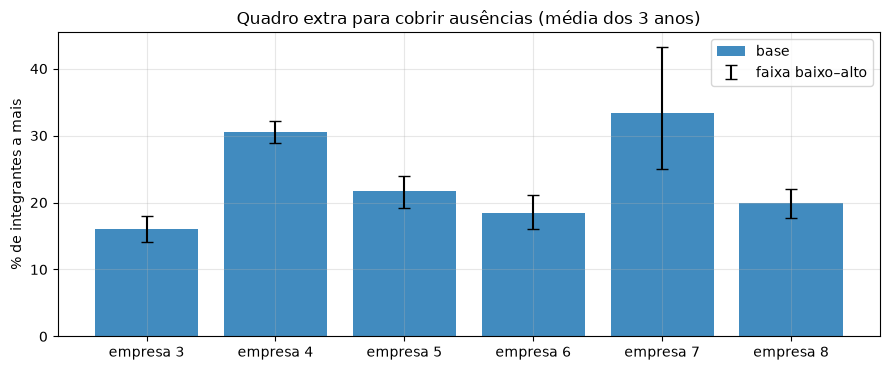

In [21]:
cen3 = por_empresa.groupby(['empresa', 'cenario']).extra_pct.mean().unstack()[['baixo', 'base', 'alto']]
fig, ax = plt.subplots(figsize=(9, 3.8)); x = np.arange(len(cen3))
ax.bar(x, cen3.base, color='C0', alpha=.85, label='base')
ax.errorbar(x, cen3.base, yerr=[cen3.base - cen3.baixo, cen3.alto - cen3.base], fmt='none', ecolor='k', capsize=4, label='faixa baixo–alto')
ax.set_xticks(x); ax.set_xticklabels([f'empresa {e}' for e in cen3.index]); ax.set_ylabel('% de integrantes a mais'); ax.legend()
ax.set_title('Quadro extra para cobrir ausências (média dos 3 anos)'); plt.tight_layout(); plt.show()

In [22]:
# sensibilidade ao nivel de servico (base, empresa a empresa, media dos 3 anos)
sens = {}
for nv in (.90, .95, .99):
    r = []
    for c in cel.itertuples():
        for ano in (1, 2, 3):
            ex, _ = extra_celula(c, 'base', ano, z=NormalDist().inv_cdf(nv)); r.append({'empresa': c.empresa, 'ex': ex, 'N': c.ativos})
    r = pd.DataFrame(r).groupby('empresa').sum(); sens[f'{int(nv*100)}%'] = (r.ex / r.N * 100).round(1)
pd.DataFrame(sens)

,90%,95%,99%
empresa,,,
3,15.0,16.0,18.0
4,26.4,30.5,39.0
5,20.8,21.6,23.2
6,17.6,18.4,19.9
7,30.8,33.4,38.5
8,19.1,19.9,21.4


A escolha do nível de serviço move o resultado em ~1 a 2 p.p. por degrau: na empresa 5, de 20,8% (90%) para 21,6% (95%) e 23,2% (99%). O efeito é bem menor que a incerteza sobre as taxas das células sem dados.

In [23]:
# salva
import os; os.makedirs('../resultados', exist_ok=True)
saida = res.merge(cel[['empresa', 'grupo', 'peso_dados']], on=['empresa', 'grupo']); saida['extra_pct'] = saida.extra / saida.ativos * 100
saida.round(3).to_csv('../resultados/trilha2_quadro_extra_por_celula.csv', index=False, encoding='utf-8-sig')
emp = por_empresa.copy(); emp.round(3).to_csv('../resultados/trilha2_quadro_extra_por_empresa.csv', index=False, encoding='utf-8-sig')
emp[emp.cenario == 'base'].pivot(index='empresa', columns='ano', values='extra_pct').round(1)

ano,1,2,3
empresa,,,
3,14.8,16.7,16.6
4,27.1,31.7,32.7
5,21.6,21.7,21.7
6,18.0,18.6,18.7
7,32.6,33.7,33.8
8,20.1,19.8,19.8


## 7. Limitações

- **76% do quadro sem dado próprio.** A empresa 5 inteira e os ônibus da empresa 8 usam a referência geral, que vem sobretudo de motoristas de caminhão da empresa 6 e de funções "demais". Ônibus e cobradores podem ter taxas diferentes. A faixa baixo–alto cobre a dispersão entre grupos observados, **mas o backtest de extrapolação (seção 3b) mostra que é estreita demais**: o erro de prever uma célula sem dado próprio é de ~5 p.p. de perda (de 1,9 a 9,6). **É o maior risco do resultado e o dado que mais o melhoraria**: o ponto e os afastamentos da empresa 5.
- **Quadro de referência.** O quadro ativo de set/2026 é usado como proxy das posições. O percentual é a medida robusta.
- **Banco de horas.** 13.211 dias sem registro de falta, abono nem batida foram tratados como compensados. Se fossem faltas, a empresa 6 subiria de ~18% para ~25%.
- **Aprendizes** ficam fora (229 ativos). Se o contrato exigir cobertura deles, é preciso um tratamento separado.
- **Afastamento prolongado incluído.** Pelo enunciado, afastamentos entram. Mas o bloco pode ser coberto por contratação temporária.
- **Taxas constantes.** Fora o efeito do tempo de casa nas férias, as taxas são as médias de 2025–2026. Não há tendência nem sazonalidade, e a base tem só 21 meses (~20 na empresa 3 e ~18 na 8, depois da limpeza). A ausência curta é maior nos primeiros meses de casa (5,1%), efeito não modelado, que subestima levemente as empresas de rotatividade alta (empresa 6).
- **Choques raros** (greve, epidemia) não estão modelados: o episódio de ponto sem registro foi tratado como dado ausente, e não como ausência real.
- **Escala.** As taxas são do cenário atual. O efeito da mudança de 6x1 para 5x2 fica para a Trilha 3.